In [1]:
import ROOT

import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interp
import scipy.optimize as opt
import matplotlib as mpl
import scipy.special as sf
import scipy.integrate as integ
import scipy.linalg as la
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)
import pandas as pd
import glob
import os
import re
import uuid
import json
import inspect




In [2]:
base_path1 = "first set sent/Results_rootonly"
index_path1 = os.path.join(base_path1, "root_index1.json")
with open(index_path1, "r") as f:
    index1 = json.load(f)

In [3]:
base_path2 = "second set sent/Results_rootonly"
index_path2 = os.path.join(base_path2, "root_index2.json")
with open(index_path2, "r") as f:
    index2 = json.load(f)

In [4]:
def process_hist(index, angle, position, hist_name, func,*args, **kwargs):
    hist_info = index[angle][position][hist_name]
    filepath = hist_info["filepath"]
    file = ROOT.TFile.Open(filepath,'READ')
    hist = file.Get(hist_name)

    if not hist:
        print("Missing:", hist_name)
        file.Close()
        return
    clone_name = f"{hist_name}_clone_{uuid.uuid4().hex}"
    hist_copy = hist.Clone(clone_name)
    hist_copy.SetDirectory(0)
    file.Close()

    try:
        sig = inspect.signature(func)
        params = sig.parameters

        optional_metadata = {
            "hist_info": hist_info,
            "angle": angle,
            "position": position,
            "hist_name": hist_name,
        }

        # Check whether func accepts arbitrary keyword arguments like **kwargs
        accepts_any_kwargs = any(
            p.kind == inspect.Parameter.VAR_KEYWORD
            for p in params.values()
        )

        if accepts_any_kwargs:
            extra_kwargs = optional_metadata
        else:
            extra_kwargs = {
                name: value
                for name, value in optional_metadata.items()
                if name in params
            }
    
        # User-provided kwargs should override automatic metadata if there is overlap
        extra_kwargs.update(kwargs)

        result = func(hist_copy, *args, **extra_kwargs)
    finally:
        hist_copy.Delete()
    return result

In [5]:
def print_hist(hist):
    for i in range(1, hist.GetNbinsX() + 1):
        print(hist.GetBinCenter(i), hist.GetBinContent(i))

In [6]:
def plot_hist(hist,angle,position,hist_name, rebin=None, ax=None, max=None):
    if rebin is not None and rebin > 1:
        if not isinstance(rebin, int):
            raise ValueError("rebin must be an integer")

        hist.Rebin(rebin)

    nbins = hist.GetNbinsX()

    x =[]
    y =[]
    width =[]

    for i in range(1, nbins + 1):
        x.append(hist.GetBinCenter(i))
        y.append(hist.GetBinContent(i))
        width.append(hist.GetBinWidth(i))
    x = np.array(x)
    y = np.array(y)
    width = np.array(width)

    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.figure

    if max is None:
        bars=ax.bar(x, y, width=width, align="center")
    else:
        lims = (x >= max[0]) & (x <= max[1])
        bars=ax.bar(x[lims], y[lims], width=width[lims], align="center")

    ax.set_xlabel("Bin center")
    ax.set_ylabel("Counts")
    ax.set_title(f"{angle}, {position}, {hist_name}")

    return fig, ax, bars

In [7]:
def max_hist(hist,gtr=None):
        nbins = hist.GetNbinsX()

        # includes underflow bin 0 and overflow bin nbins+1
        all_contents = np.asarray(hist.GetArray(), dtype=float)

        # keep only normal bins
        values = all_contents[1:nbins + 1].copy()
        if gtr==None:
            mx=np.max(values)
            print(mx)
            i=int(np.where(values==mx)[0][0])+1
            print(hist.GetBinCenter(i), hist.GetBinContent(i))
            print(nbins)
        else:
              i=np.where(values>gtr)[0]+1
              print(nbins)
              for a in range(len(i)):
                print(hist.GetBinCenter(int(i[a])), hist.GetBinContent(int(i[a])))
        del values
        return(i)


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import re

def Time_density_hist(index, angle, position, rebin=None,freq_range=None):

    def get_time_from_key(key):
        nums = re.findall(r"-?\d+\.?\d*", key)
        if len(nums) == 0:
            raise ValueError(f"No time/index number found in key: {key}")
        return float(nums[0])

    def histout(hist, hist_info):
        if rebin is not None and rebin > 1:
            old_level = ROOT.gErrorIgnoreLevel
            ROOT.gErrorIgnoreLevel = ROOT.kError

            hist.Rebin(rebin)

            ROOT.gErrorIgnoreLevel = old_level

        nbins = hist.GetNbinsX()

        counts = np.array([
            hist.GetBinContent(i)
            for i in range(1, nbins + 1)
        ])

        freq_edges = np.array(
            [hist.GetBinLowEdge(i) for i in range(1, nbins + 1)]
            + [hist.GetBinLowEdge(nbins) + hist.GetBinWidth(nbins)]
        )

        return counts, freq_edges

    psd_keys = [
        key for key in index[angle][position]
        if "PSD" in key
    ]

    psd_keys = sorted(psd_keys, key=get_time_from_key)
    times = []
    rows = []
    freq_edges = None

    for key in psd_keys:
        time = get_time_from_key(key)

        counts, edges = process_hist(index, angle, position, key, histout)

        times.append(time)
        rows.append(counts)

        if freq_edges is None:
            freq_edges = edges
    times = np.array(times)
    data = np.array(rows)
    if freq_range is not None:
        freq_centers = 0.5 * (freq_edges[:-1] + freq_edges[1:])
        lims = (freq_centers >= freq_range[0]) & (freq_centers <= freq_range[1])
        idx = np.where(lims)[0]

        first = idx[0]
        last = idx[-1]

        data = data[:, first:last + 1]
        freq_edges = freq_edges[first:last + 2]
    data = data.T

    # Make time bin edges from time centers
    if len(times) > 1:
        time_edges = np.zeros(len(times) + 1)
        time_edges[1:-1] = 0.5 * (times[:-1] + times[1:])
        time_edges[0] = times[0] - 0.5 * (times[1] - times[0])
        time_edges[-1] = times[-1] + 0.5 * (times[-1] - times[-2])
    else:
        time_edges = np.array([times[0] - 0.5, times[0] + 0.5])

    fig, ax = plt.subplots(figsize=(8, 6))

    mesh = ax.pcolormesh(
        time_edges,
        freq_edges,
        data,
        shading="auto"
    )

    fig.colorbar(mesh, ax=ax, label="Counts")

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency")
    ax.set_title(f"PSD density map: angle={angle}, position={position}")
    del data
    del rows
    del times


In [9]:
# def angle_density_hist(index,position,rebin,freq_range=[1e8,2e8]):
    

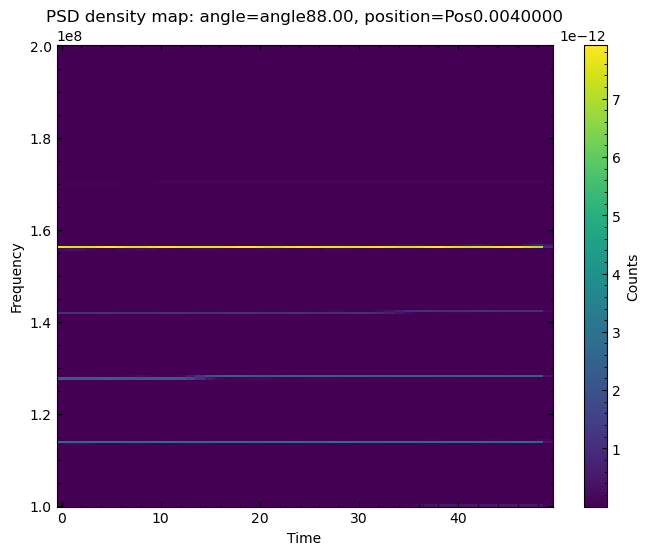

In [12]:
Time_density_hist(index2, 'angle88.00', 'Pos0.0040000', rebin=10,freq_range=[1e8,2e8])